<a href="https://colab.research.google.com/github/fatmaemad8/RSRP_RSSI-Prediction/blob/main/Copy_of_RSRP_RSSI_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import subprocess
import shutil
import os

# Clone the specific branch into the Colab environment
branch_name = "HODA-ELTOHAMI"
repo_url = "https://github.com/fatmaemad8/RSRP_RSSI-Prediction.git"
target_dir = "RSRP_RSSI-Prediction"

# Remove the directory if it already exists to avoid conflict
if os.path.exists(target_dir):
    shutil.rmtree(target_dir)

subprocess.run(["git", "clone", "-b", branch_name, repo_url], check=True)

CompletedProcess(args=['git', 'clone', '-b', 'HODA-ELTOHAMI', 'https://github.com/fatmaemad8/RSRP_RSSI-Prediction.git'], returncode=0)

In [35]:
import pandas as pd

# Load the dataset from the cloned branch directory
df = pd.read_csv("RSRP_RSSI-Prediction/ml.csv")

# Display dataset shape and first few rows
print("Shape:", df.shape)
print(df.head(3))

Shape: (56602, 15)
      timestamp  rel_time  longitude   latitude  altitude  pci           ci  \
0  1.693070e+12  1.014608 -78.666622  35.786425     4.216  171    195616280   
1  1.693070e+12  1.014654 -78.666622  35.786425     4.216  192  Unavailable   
2  1.693070e+12  1.014688 -78.666622  35.786425     4.216   31  Unavailable   

   is_connected          tac  earfcn  rsrp  rsrq  rssi  asu           ta  
0             1         9995   66486  -104   -15   -71   36  Unavailable  
1             0  Unavailable   66486  -104   -11   -83   36  Unavailable  
2             0  Unavailable   66486  -113   -20   -83   27  Unavailable  


In [36]:
import numpy as np

# Convert "Unavailable" string to actual NaN values
df = df.replace("Unavailable", np.nan)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nMissing values count per column:")
print(df.isna().sum())

Dataset Shape: (56602, 15)

First 5 rows:
      timestamp  rel_time  longitude   latitude  altitude  pci         ci  \
0  1.693070e+12  1.014608 -78.666622  35.786425     4.216  171  195616280   
1  1.693070e+12  1.014654 -78.666622  35.786425     4.216  192        NaN   
2  1.693070e+12  1.014688 -78.666622  35.786425     4.216   31        NaN   
3  1.693070e+12  1.014718 -78.666622  35.786425     4.216  198        NaN   
4  1.693070e+12  2.035097 -78.666622  35.786425     4.216  171  195616280   

   is_connected   tac  earfcn  rsrp  rsrq  rssi  asu   ta  
0             1  9995   66486  -104   -15   -71   36  NaN  
1             0   NaN   66486  -104   -11   -83   36  NaN  
2             0   NaN   66486  -113   -20   -83   27  NaN  
3             0   NaN   66486  -108   -15   -83   32  NaN  
4             1  9995   66486  -103   -15   -69   37  NaN  

Missing values count per column:
timestamp           0
rel_time            0
longitude           0
latitude            0
altitude     

In [37]:
missing_pct = (df.isna().sum() / len(df)) * 100
summary = pd.DataFrame({
    "Dtype": df.dtypes,
    "Missing_Count": df.isna().sum(),
    "Missing_%": missing_pct.round(2),
})
print(summary)

                Dtype  Missing_Count  Missing_%
timestamp     float64              0       0.00
rel_time      float64              0       0.00
longitude     float64              0       0.00
latitude      float64              0       0.00
altitude      float64              0       0.00
pci             int64              0       0.00
ci             object          50222      88.73
is_connected    int64              0       0.00
tac            object          50222      88.73
earfcn          int64              0       0.00
rsrp            int64              0       0.00
rsrq            int64              0       0.00
rssi            int64              0       0.00
asu             int64              0       0.00
ta             object           9076      16.03


In [38]:
df_clean = df.drop(columns=["ci", "tac"]).copy()
df_clean["ta"] = pd.to_numeric(df_clean["ta"], errors="coerce")

print(df_clean.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56602 entries, 0 to 56601
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     56602 non-null  float64
 1   rel_time      56602 non-null  float64
 2   longitude     56602 non-null  float64
 3   latitude      56602 non-null  float64
 4   altitude      56602 non-null  float64
 5   pci           56602 non-null  int64  
 6   is_connected  56602 non-null  int64  
 7   earfcn        56602 non-null  int64  
 8   rsrp          56602 non-null  int64  
 9   rsrq          56602 non-null  int64  
 10  rssi          56602 non-null  int64  
 11  asu           56602 non-null  int64  
 12  ta            47526 non-null  float64
dtypes: float64(6), int64(7)
memory usage: 5.6 MB
None


In [39]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Clean the data
df_clean = df.drop(columns=["ci", "tac"]).copy()
df_clean["ta"] = pd.to_numeric(df_clean["ta"], errors="coerce")
df_clean["ta"] = df_clean["ta"].fillna(df_clean["ta"].median())

# 2. Define features (X) and targets (y_rsrp and y_rssi)
X = df_clean.drop(columns=["rsrp", "rssi", "asu"])
y_rsrp = df_clean["rsrp"]
y_rssi = df_clean["rssi"]

# 3. Split the data once maintaining same row indices
X_train, X_test, y_rsrp_train, y_rsrp_test, y_rssi_train, y_rssi_test = (
    train_test_split(X, y_rsrp, y_rssi, test_size=0.2, random_state=42)
)

# 4. RSRP Prediction Model
model_rsrp = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
model_rsrp.fit(X_train, y_rsrp_train)
pred_rsrp = model_rsrp.predict(X_test)

print("=== RSRP Prediction Results ===")
print("Mean Absolute Error (MAE):", round(mean_absolute_error(y_rsrp_test, pred_rsrp), 2))
print("R-squared (R2):", round(r2_score(y_rsrp_test, pred_rsrp), 4))

# 5. RSSI Prediction Model
model_rssi = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
model_rssi.fit(X_train, y_rssi_train)
pred_rssi = model_rssi.predict(X_test)

print("\n=== RSSI Prediction Results ===")
print("Mean Absolute Error (MAE):", round(mean_absolute_error(y_rssi_test, pred_rssi), 2))
print("R-squared (R2):", round(r2_score(y_rssi_test, pred_rssi), 4))

=== RSRP Prediction Results ===
Mean Absolute Error (MAE): 0.67
R-squared (R2): 0.9914

=== RSSI Prediction Results ===
Mean Absolute Error (MAE): 0.51
R-squared (R2): 0.9906


In [40]:
# Display the dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56602 entries, 0 to 56601
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     56602 non-null  float64
 1   rel_time      56602 non-null  float64
 2   longitude     56602 non-null  float64
 3   latitude      56602 non-null  float64
 4   altitude      56602 non-null  float64
 5   pci           56602 non-null  int64  
 6   ci            6380 non-null   object 
 7   is_connected  56602 non-null  int64  
 8   tac           6380 non-null   object 
 9   earfcn        56602 non-null  int64  
 10  rsrp          56602 non-null  int64  
 11  rsrq          56602 non-null  int64  
 12  rssi          56602 non-null  int64  
 13  asu           56602 non-null  int64  
 14  ta            47526 non-null  object 
dtypes: float64(5), int64(7), object(3)
memory usage: 6.5+ MB


In [41]:
# Count missing values in each column
df.isnull().sum()

,0
timestamp,0
rel_time,0
longitude,0
latitude,0
altitude,0
pci,0
ci,50222
is_connected,0
tac,50222
earfcn,0


In [42]:
# Generate descriptive statistics for numerical columns
df.describe()

,timestamp,rel_time,longitude,latitude,altitude,pci,is_connected,earfcn,rsrp,rsrq,rssi,asu
count,5.660200e+04,56602.000000,56602.000000,56602.000000,56602.00000,56602.000000,56602.000000,56602.000000,56602.000000,56602.000000,56602.000000,56602.000000
mean,1.693070e+12,3038.306111,-78.666525,35.786410,33.35525,197.884651,0.112717,27360.987439,-97.799565,-16.849793,-69.645136,42.200435
std,0.000000e+00,1856.068234,0.000222,0.000166,43.60487,132.568429,0.316249,31463.614949,10.827453,2.518969,11.150032,10.827453
min,1.693070e+12,1.014608,-78.666820,35.785709,3.50400,0.000000,0.000000,950.000000,-127.000000,-20.000000,-97.000000,13.000000
25%,1.693070e+12,1445.315408,-78.666638,35.786387,5.58700,76.000000,0.000000,950.000000,-106.000000,-19.000000,-79.000000,34.000000
50%,1.693070e+12,2912.712429,-78.666622,35.786415,7.21300,171.000000,0.000000,5110.000000,-102.000000,-17.000000,-75.000000,38.000000
75%,1.693070e+12,4624.774565,-78.666587,35.786439,53.77100,287.000000,0.000000,66486.000000,-87.000000,-15.000000,-57.000000,53.000000
max,1.693070e+12,6428.598749,-78.665740,35.787103,135.18300,502.000000,1.000000,67086.000000,-68.000000,-8.000000,-51.000000,72.000000


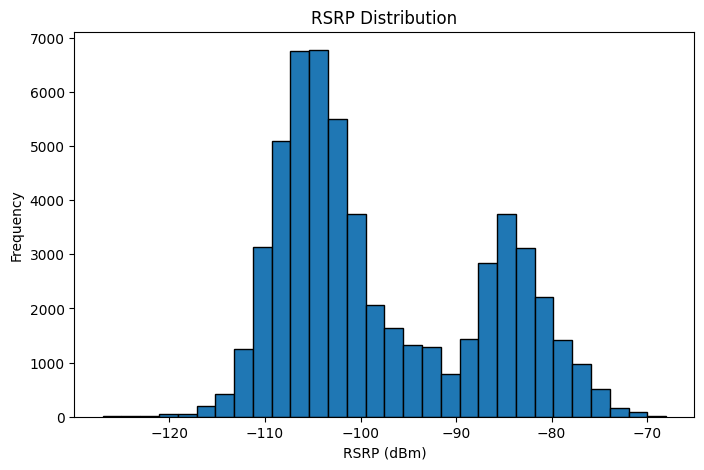

In [43]:
# Import the visualization library
import matplotlib.pyplot as plt

# Create a histogram for RSRP values
plt.figure(figsize=(8, 5))
plt.hist(df['rsrp'], bins=30, edgecolor='black')

# Add chart title and axis labels
plt.title('RSRP Distribution')
plt.xlabel('RSRP (dBm)')
plt.ylabel('Frequency')

# Display the chart
plt.show()

The RSRP distribution shows a bimodal pattern with two distinct peaks, approximately around -105 dBm and -84 dBm. This suggests that the dataset contains measurements under different signal-strength conditions. Further analysis is needed to investigate the factors contributing to these two groups.

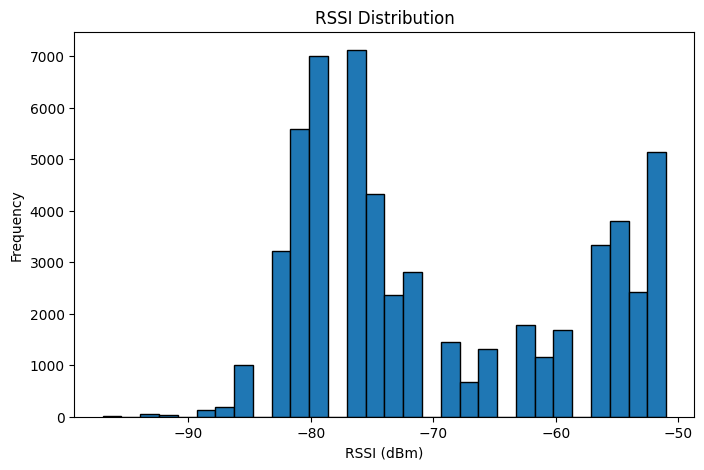

In [44]:
# Create a histogram for RSSI values
plt.figure(figsize=(8, 5))
plt.hist(df['rssi'], bins=30, edgecolor='black')

# Add chart title and axis labels
plt.title('RSSI Distribution')
plt.xlabel('RSSI (dBm)')
plt.ylabel('Frequency')

# Display the chart
plt.show()

The RSSI distribution exhibits a multimodal pattern, with major concentrations around -80 to -74 dBm and -57 to -51 dBm. This indicates variations in received signal strength across the collected measurements.

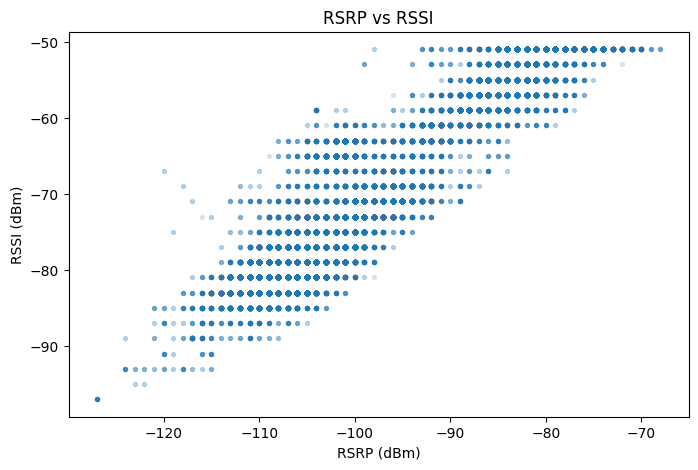

In [45]:
# Create a scatter plot to examine the relationship between RSRP and RSSI
plt.figure(figsize=(8, 5))

plt.scatter(df['rsrp'], df['rssi'], alpha=0.15, s=8)

# Add chart title and axis labels
plt.title('RSRP vs RSSI')
plt.xlabel('RSRP (dBm)')
plt.ylabel('RSSI (dBm)')

# Display the chart
plt.show()

The scatter plot reveals a strong positive relationship between RSRP and RSSI. As RSRP increases (becomes less negative), RSSI generally increases as well. This indicates that both measurements tend to improve under better signal reception conditions.

In [46]:
# Calculate the Pearson correlation between RSRP and RSSI
correlation = df['rsrp'].corr(df['rssi'])

# Display the correlation coefficient
print("RSRP-RSSI Correlation:", correlation)

RSRP-RSSI Correlation: 0.946537686506144


The Pearson correlation coefficient between RSRP and RSSI is 0.9465, indicating a very strong positive linear relationship between the two signal measurements.

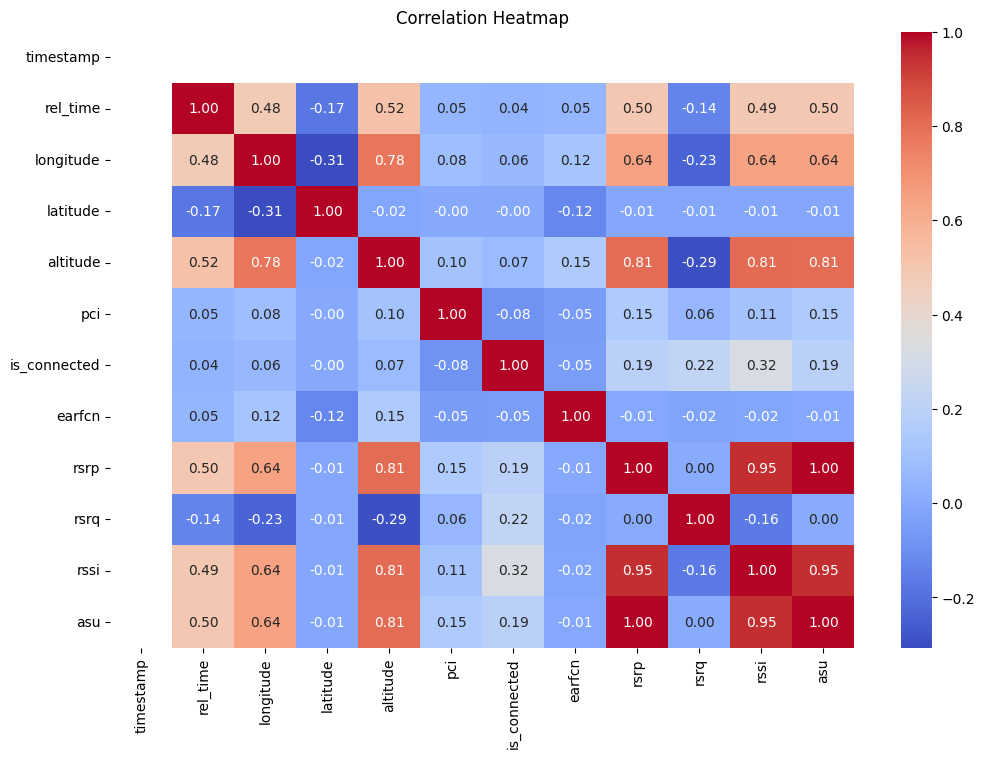

In [47]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate the correlation matrix
corr_matrix = numeric_df.corr()

# Create the correlation heatmap
plt.figure(figsize=(12, 8))
import seaborn as sns

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

# Add chart title
plt.title('Correlation Heatmap')

# Display the chart
plt.show()

The correlation heatmap reveals several important relationships between the dataset features.

- RSRP has a very strong positive correlation with RSSI (0.95).
- Altitude shows a strong positive correlation with RSRP (0.81) and RSSI (0.81).
- Longitude has a moderate positive correlation with RSRP (0.64).
- RSRQ has almost no linear correlation with RSRP (0.00).
- ASU has a perfect correlation with RSRP (1.00), indicating that both measurements carry essentially the same information in this dataset.

These results highlight the relationships between signal measurements and flight-related variables. However, correlation does not necessarily imply causation.

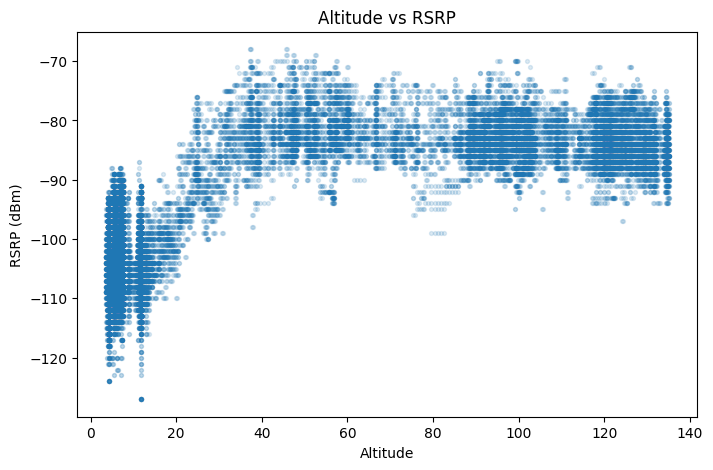

In [48]:
# Create a scatter plot to examine the relationship between Altitude and RSRP
plt.figure(figsize=(8, 5))

plt.scatter(df['altitude'], df['rsrp'], alpha=0.15, s=8)

# Add chart title and axis labels
plt.title('Altitude vs RSRP')
plt.xlabel('Altitude')
plt.ylabel('RSRP (dBm)')

# Display the chart
plt.show()

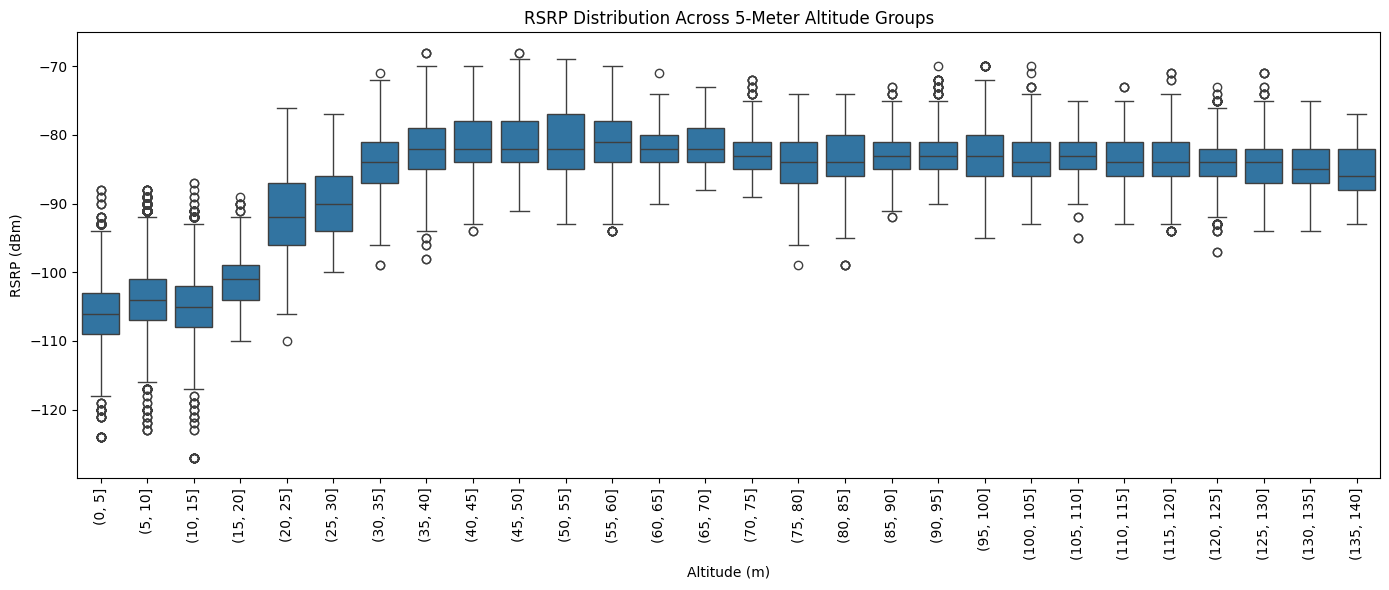

In [49]:
# Create altitude groups using 5-meter intervals
df['altitude_5m'] = pd.cut(
    df['altitude'],
    bins=range(0, 141, 5)
)

# Create a box plot for RSRP across altitude groups
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x='altitude_5m',
    y='rsrp'
)

# Add chart title and axis labels
plt.title('RSRP Distribution Across 5-Meter Altitude Groups')
plt.xlabel('Altitude (m)')
plt.ylabel('RSRP (dBm)')

# Rotate x-axis labels
plt.xticks(rotation=90)

# Display the chart
plt.tight_layout()
plt.show()

The boxplot shows a clear improvement in RSRP with increasing altitude, particularly between 20 and 35 meters. The median RSRP improves from approximately -106 dBm at low altitudes to around -82 dBm above 30 meters. At lower altitudes, the measurements exhibit greater variability and several low-value outliers. Above approximately 35 meters, the RSRP distribution becomes relatively stable, with medians remaining around -82 to -85 dBm.

However, the number of observations varies substantially across altitude groups. Therefore, results from groups with fewer samples should be interpreted with caution.

In [50]:
# Count the number of samples in each altitude group
altitude_counts = df['altitude_5m'].value_counts().sort_index()

# Display the sample counts
print(altitude_counts)

altitude_5m
(0, 5]         7993
(5, 10]       24553
(10, 15]       6009
(15, 20]        457
(20, 25]        416
(25, 30]        348
(30, 35]        379
(35, 40]        709
(40, 45]        360
(45, 50]        674
(50, 55]        677
(55, 60]        764
(60, 65]        342
(65, 70]        281
(70, 75]        342
(75, 80]        256
(80, 85]        240
(85, 90]        869
(90, 95]       1137
(95, 100]      1402
(100, 105]     1143
(105, 110]      514
(110, 115]      404
(115, 120]     1213
(120, 125]     2122
(125, 130]     1434
(130, 135]     1493
(135, 140]       71
Name: count, dtype: int64


The number of observations varies substantially across altitude groups, with the largest concentration between 5 and 15 meters. Therefore, comparisons involving groups with relatively few observations should be interpreted with caution.

In [51]:
# Calculate RSRP statistics for each altitude group
altitude_stats = df.groupby('altitude_5m', observed=True)['rsrp'].agg(
    Median='median',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)

# Display the statistics
print(altitude_stats)

             Median     Q1     Q3
altitude_5m                      
(0, 5]       -106.0 -109.0 -103.0
(5, 10]      -104.0 -107.0 -101.0
(10, 15]     -105.0 -108.0 -102.0
(15, 20]     -101.0 -104.0  -99.0
(20, 25]      -92.0  -96.0  -87.0
(25, 30]      -90.0  -94.0  -86.0
(30, 35]      -84.0  -87.0  -81.0
(35, 40]      -82.0  -85.0  -79.0
(40, 45]      -82.0  -84.0  -78.0
(45, 50]      -82.0  -84.0  -78.0
(50, 55]      -82.0  -85.0  -77.0
(55, 60]      -81.0  -84.0  -78.0
(60, 65]      -82.0  -84.0  -80.0
(65, 70]      -82.0  -84.0  -79.0
(70, 75]      -83.0  -85.0  -81.0
(75, 80]      -84.0  -87.0  -81.0
(80, 85]      -84.0  -86.0  -80.0
(85, 90]      -83.0  -85.0  -81.0
(90, 95]      -83.0  -85.0  -81.0
(95, 100]     -83.0  -86.0  -80.0
(100, 105]    -84.0  -86.0  -81.0
(105, 110]    -83.0  -85.0  -81.0
(110, 115]    -84.0  -86.0  -81.0
(115, 120]    -84.0  -86.0  -81.0
(120, 125]    -84.0  -86.0  -82.0
(125, 130]    -84.0  -87.0  -82.0
(130, 135]    -85.0  -87.0  -82.0
(135, 140]    

RSRP improves substantially with altitude up to approximately 35–40 meters, after which the median RSRP remains relatively stable around −82 to −85 dBm, with a slight decrease at the highest altitude ranges.

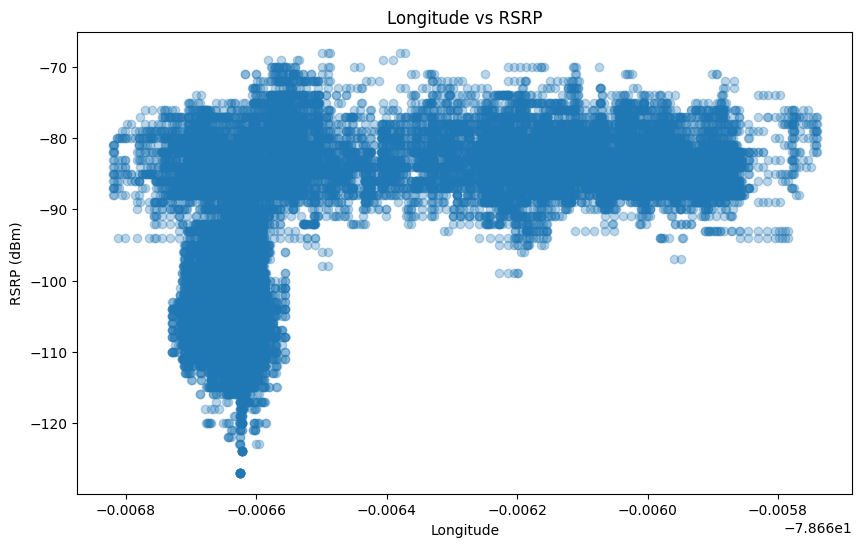

In [52]:
# Create a scatter plot to examine the relationship between longitude and RSRP
plt.figure(figsize=(10, 6))

plt.scatter(
    df['longitude'],
    df['rsrp'],
    alpha=0.3
)

# Add chart title and axis labels
plt.title('Longitude vs RSRP')
plt.xlabel('Longitude')
plt.ylabel('RSRP (dBm)')

# Display the plot
plt.show()

The Longitude vs. RSRP scatter plot exhibits an L-shaped distribution, with weak signal measurements concentrated within a narrow longitude range. However, longitude is strongly correlated with altitude (r = 0.78), suggesting that the observed relationship between longitude and RSRP (r = 0.64) may be influenced by the drone's movement and increasing altitude during the survey. Therefore, longitude should not be interpreted as an independent factor affecting RSRP based on this plot alone.

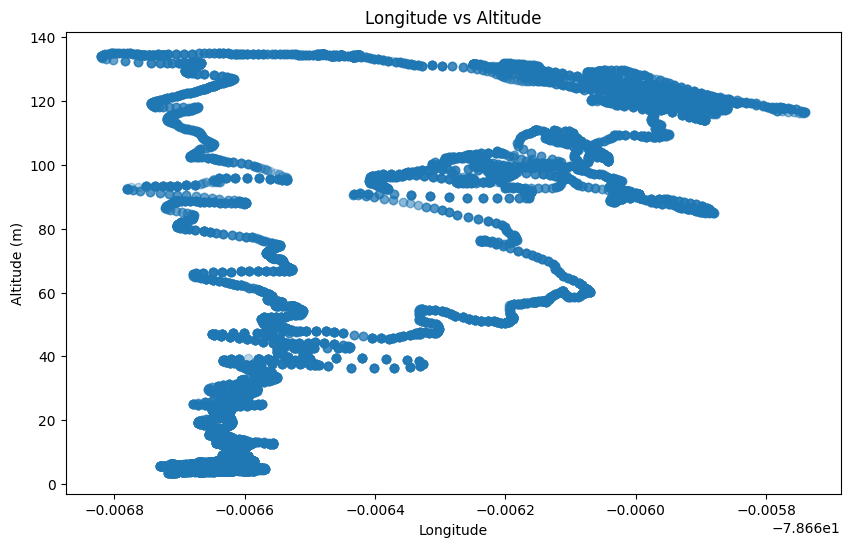

In [53]:
# Create a scatter plot to examine the relationship between longitude and altitude
plt.figure(figsize=(10, 6))

plt.scatter(
    df['longitude'],
    df['altitude'],
    alpha=0.3
)

# Add chart title and axis labels
plt.title('Longitude vs Altitude')
plt.xlabel('Longitude')
plt.ylabel('Altitude (m)')

# Display the plot
plt.show()

The Longitude vs. Altitude scatter plot reveals a single continuous flight trajectory, starting at low altitude and gradually climbing before performing horizontal traverses and loops at higher altitudes. The trajectory is spatially constrained, particularly below 60 meters, which helps explain the concentration of weak RSRP measurements within a narrow longitude range. This indicates that altitude and longitude are strongly intertwined in the dataset, and their individual effects on signal strength cannot be reliably separated using simple correlation analysis alone.

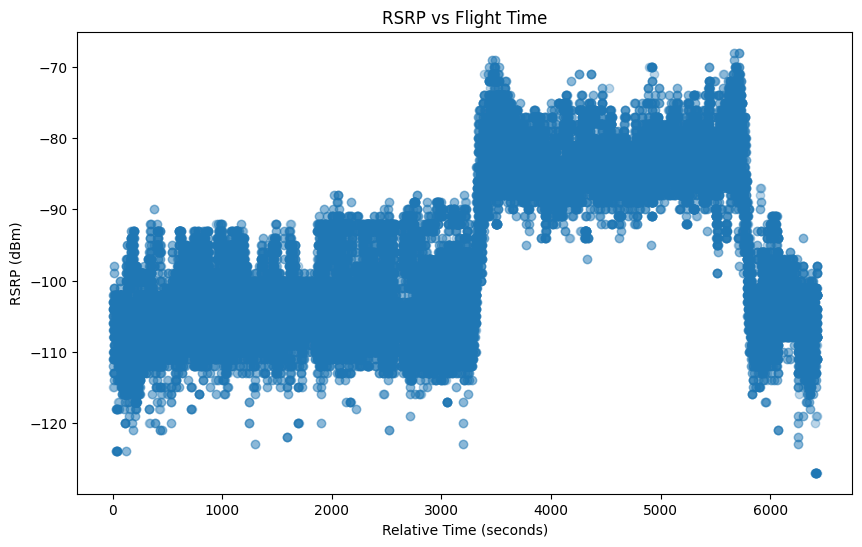

In [54]:
# Create a scatter plot to examine RSRP changes over flight time
plt.figure(figsize=(10, 6))

plt.scatter(
    df['rel_time'],
    df['rsrp'],
    alpha=0.3
)

# Add chart title and axis labels
plt.title('RSRP vs Flight Time')
plt.xlabel('Relative Time (seconds)')
plt.ylabel('RSRP (dBm)')

# Display the plot
plt.show()

In [55]:
# Divide the flight into three time phases
df['flight_phase'] = pd.cut(
    df['rel_time'],
    bins=[0, 3300, 5700, 6500],
    labels=['Phase 1', 'Phase 2', 'Phase 3']
)

# Calculate median altitude and RSRP for each phase
phase_analysis = df.groupby(
    'flight_phase',
    observed=True
).agg(
    Median_Altitude=('altitude', 'median'),
    Median_RSRP=('rsrp', 'median'),
    Sample_Count=('rsrp', 'count')
)

# Display the results
print(phase_analysis)

              Median_Altitude  Median_RSRP  Sample_Count
flight_phase                                            
Phase 1                5.7700       -105.0         32979
Phase 2               99.4825        -84.0         17054
Phase 3               11.7150       -104.0          6569


The flight data shows three distinct phases. During Phase 1, the median RSRP was -105 dBm at a median altitude of 5.77 m. In Phase 2, the median RSRP improved to -84 dBm as the median altitude increased to 99.48 m. During Phase 3, the median RSRP decreased to -104 dBm while the median altitude dropped to 11.72 m.

This suggests an association between altitude and signal strength in this flight dataset. However, other factors, such as location and serving cell conditions, may also affect RSRP.

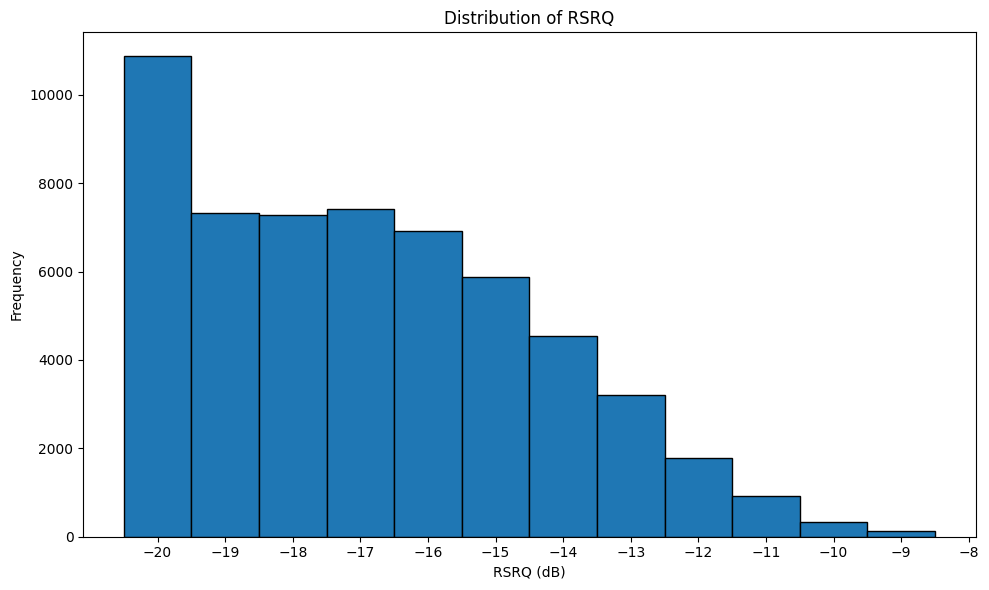

In [56]:
# Plot the distribution of RSRQ
plt.figure(figsize=(10, 6))

plt.hist(
    df['rsrq'],
    bins=np.arange(-20.5, -7.5, 1),
    edgecolor='black'
)

# Add chart title and axis labels
plt.title('Distribution of RSRQ')
plt.xlabel('RSRQ (dB)')
plt.ylabel('Frequency')

plt.xticks(range(-20, -7))
plt.tight_layout()
plt.show()

The RSRQ distribution is concentrated at lower values, with a clear peak at -20 dB. The frequency generally decreases as RSRQ values increase toward -8 dB, indicating that high RSRQ values are relatively uncommon in this dataset.

In [57]:
# Check the unique RSRQ values and their frequencies
print(df['rsrq'].value_counts().sort_index())

rsrq
-20    10872
-19     7316
-18     7284
-17     7418
-16     6910
-15     5877
-14     4538
-13     3210
-12     1782
-11      925
-10      322
-9       130
-8        18
Name: count, dtype: int64


The RSRQ distribution is concentrated toward lower values, with the highest frequency occurring at −20 dB (10,872 samples). The median is approximately −17 dB, and the frequency generally decreases toward higher RSRQ values. Only a small proportion of measurements exceed −10 dB. The accumulation at −20 dB may indicate a lower measurement limit or floor effect, although this requires confirmation from the measurement device specifications.